In [19]:
!pip install tensorflow matplotlib numpy
# Feedforward Neural Network using TensorFlow and Keras

# Step 1: Import required libraries
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense




In [20]:
# Step 2: Load the MNIST dataset
print("Loading MNIST dataset...")

(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("Dataset loaded successfully!")
print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)



Loading MNIST dataset...
Dataset loaded successfully!
Training data shape: (60000, 28, 28)
Testing data shape: (10000, 28, 28)


In [21]:
# Step 3: Normalize the pixel values between 0 and 1
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Step 4: Define the feedforward neural network
model = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax")
])



In [22]:
# Step 5: Compile the model using SGD optimizer
model.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.01),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display model architecture
model.summary()



Model: "sequential_5"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten_5 (Flatten)         (None, 784)               0         
                                                                 
 dense_10 (Dense)            (None, 64)                50240     
                                                                 
 dense_11 (Dense)            (None, 10)                650       
                                                                 
Total params: 50,890
Trainable params: 50,890
Non-trainable params: 0
_________________________________________________________________


In [23]:
# Step 6: Train the model
print("\nTraining the model...")

history = model.fit(
    x_train,
    y_train,
    epochs=3,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)




Training the model...
Epoch 1/3
422/422 [==============================] - 0s 888us/step - loss: 1.2858 - accuracy: 0.6810 - val_loss: 0.6593 - val_accuracy: 0.8733
Epoch 2/3
422/422 [==============================] - 0s 778us/step - loss: 0.6015 - accuracy: 0.8562 - val_loss: 0.4328 - val_accuracy: 0.9025
Epoch 3/3
422/422 [==============================] - 0s 751us/step - loss: 0.4702 - accuracy: 0.8786 - val_loss: 0.3597 - val_accuracy: 0.9113


In [24]:
# Step 7: Evaluate the model on test data
print("\nEvaluating the model...")

test_loss, test_accuracy = model.evaluate(
    x_test, y_test, verbose=0
)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")




Evaluating the model...
Test Loss: 0.4083
Test Accuracy: 89.35 %


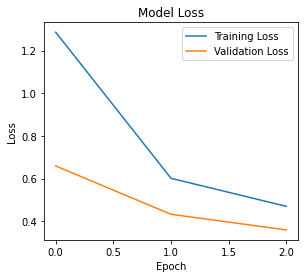

In [25]:
# Step 8: Plot training and validation loss
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()



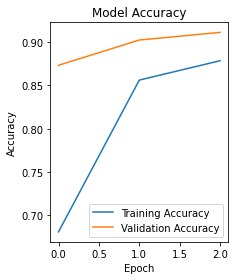

In [26]:
# Step 9: Plot training and validation accuracy
plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()
